## 掛載雲端硬碟


In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## 更改檔案所在路徑

In [2]:
# Change to your own folder !!!
%cd /content/drive/MyDrive/EAI-Lab-2/

/content/drive/MyDrive/EAI-Lab-2


## Import library

In [3]:
import torch
from models.resnet import ResNet50
from torch import nn, optim
from torch.autograd import Variable
from torchvision import datasets, transforms


## 設定超參數

In [4]:
SEED = 1
TRAIN_BATCH_SIZE = 100
TEST_BATCH_SIZE = 1000
EPOCHS = 20
LEARNING_RATE = 1e-3
LOG_INTERVAL = 100
CUDA = True

RESUME = True
START_EPOCH = 0

PRUNE_PATH = "/content/drive/MyDrive/EAI-Lab-2/weights/model_prune.pth"  # Change to your own folder !!!
PRUNE_FINETUNE_PATH = "/content/drive/MyDrive/EAI-Lab-2/weights/model_prune_finetune.pth"  # Change to your own folder !!!


#### 檢查是否檢查是否可使用GPU

In [5]:
if torch.cuda.is_available():
    CUDA = True
    kwargs = {"num_workers": 1, "pin_memory": True}
    torch.cuda.manual_seed(SEED)
else:
    CUDA = False
    kwargs = {}


## 下載資料集


這裡將訓練集做Augmentation(Pad, RandCrop, Random)，測試集不用做Augmentation

In [6]:
#### DATASET ####
train_loader = torch.utils.data.DataLoader(
    datasets.CIFAR10(
        "./data",
        train=True,
        download=True,
        transform=transforms.Compose(
            [
                transforms.Pad(4),
                transforms.RandomCrop(32),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor(),
                transforms.Normalize(
                    (0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)
                ),
            ]
        ),
    ),
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    **kwargs,
)
test_loader = torch.utils.data.DataLoader(
    datasets.CIFAR10(
        "./data",
        train=False,
        transform=transforms.Compose(
            [
                transforms.ToTensor(),
                transforms.Normalize(
                    (0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)
                ),
            ]
        ),
    ),
    batch_size=TEST_BATCH_SIZE,
    shuffle=True,
    **kwargs,
)

## 載入剪枝後的網路與權重

In [7]:
model = None
if RESUME:
    checkpoint = torch.load(PRUNE_PATH)
    cfg = checkpoint["cfg"]
    model = ResNet50(num_classes=10, cfg=cfg)
    model.load_state_dict(checkpoint["state_dict"])

    print("RESUME PRUNE MODEL")

if CUDA:
    model.cuda()

RESUME PRUNE MODEL


## 設定 Optimizer & CrossEntropy Loss

In [8]:
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

## 定義訓練跟測試函數

In [9]:
#### 訓練函數 #####

# 注意: 需自行撰寫儲存每個 epoch 之 train acc 的 code，以便後續繪製 train acc 結果圖!

history = {
    "train_losses": [],
    "train_accuracies": [],
    "test_accuracies": [],
}


def train(epoch):
    model.train()
    train_loss = 0.0
    train_correct = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        if CUDA:
            data, target = data.cuda(), target.cuda()
        data, target = Variable(data), Variable(target)

        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        pred = output.data.max(1, keepdim=True)[1]
        train_loss += loss.item() * data.size(0)
        train_correct += pred.eq(target.data.view_as(pred)).cpu().sum().item()

        if batch_idx % LOG_INTERVAL == 0:
            print(
                f"\nTrain Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} ({100.0 * batch_idx / len(train_loader):.1f}%)]\tLoss: {loss.data.item():.6f}"
            )
    history["train_losses"].append(train_loss / len(train_loader.dataset))
    history["train_accuracies"].append(train_correct / len(train_loader.dataset))


#### 測試函數 ####
def test():
    model.eval()
    test_loss = 0
    test_correct = 0

    with torch.no_grad():
        for data, target in test_loader:
            if CUDA:
                data, target = data.cuda(), target.cuda()
            data, target = Variable(data), Variable(target)

            output = model(data)
            loss = criterion(output, target)
            test_loss += loss.item() * data.size(0)

            pred = output.data.max(1, keepdim=True)[1]
            test_correct += pred.eq(target.data.view_as(pred)).cpu().sum().item()

        test_loss /= len(test_loader.dataset)

        print(
            f"\nTest set: Average loss: {test_loss:.4f}, Accuracy: {test_correct}/{len(test_loader.dataset)} ({100.0 * test_correct / len(test_loader.dataset):.1f}%)\n"
        )
        return test_correct / float(len(test_loader.dataset))


best_prec1 = 0.0
for epoch in range(START_EPOCH, EPOCHS):
    # Learning Rate 在 0.5EPOCHS 與 0.75EPOCHS 調整為原本之十分之一
    if epoch in [EPOCHS * 0.5, EPOCHS * 0.75]:
        for param_group in optimizer.param_groups:
            param_group["lr"] *= 0.1
    train(epoch)
    prec1 = test()
    history["test_accuracies"].append(prec1)

    # 儲存模型權重
    if prec1 > best_prec1:
        best_prec1 = prec1
        torch.save(
            {
                "epoch": epoch + 1,
                "state_dict": model.state_dict(),
                "best_prec1": best_prec1,
                "optimizer": optimizer.state_dict(),
                "cfg": cfg,
            },
            PRUNE_FINETUNE_PATH,
        )

    best_prec1 = max(prec1, best_prec1)

print("\n TRAIN PRUNED MODEL DONE!")



Train Epoch: 0 [0/50000 (0.0%)]	Loss: 0.143942

Train Epoch: 0 [10000/50000 (20.0%)]	Loss: 0.333910

Train Epoch: 0 [20000/50000 (40.0%)]	Loss: 0.264719

Train Epoch: 0 [30000/50000 (60.0%)]	Loss: 0.244423

Train Epoch: 0 [40000/50000 (80.0%)]	Loss: 0.409018

Test set: Average loss: 0.4471, Accuracy: 8560/10000 (85.6%)


Train Epoch: 1 [0/50000 (0.0%)]	Loss: 0.315529

Train Epoch: 1 [10000/50000 (20.0%)]	Loss: 0.338670

Train Epoch: 1 [20000/50000 (40.0%)]	Loss: 0.350027

Train Epoch: 1 [30000/50000 (60.0%)]	Loss: 0.153659

Train Epoch: 1 [40000/50000 (80.0%)]	Loss: 0.408461

Test set: Average loss: 0.4020, Accuracy: 8675/10000 (86.8%)


Train Epoch: 2 [0/50000 (0.0%)]	Loss: 0.256156

Train Epoch: 2 [10000/50000 (20.0%)]	Loss: 0.334424

Train Epoch: 2 [20000/50000 (40.0%)]	Loss: 0.284620

Train Epoch: 2 [30000/50000 (60.0%)]	Loss: 0.174605

Train Epoch: 2 [40000/50000 (80.0%)]	Loss: 0.295279

Test set: Average loss: 0.4354, Accuracy: 8571/10000 (85.7%)


Train Epoch: 3 [0/50000 (0.0%)

## 繪製Fine-tuning結果圖


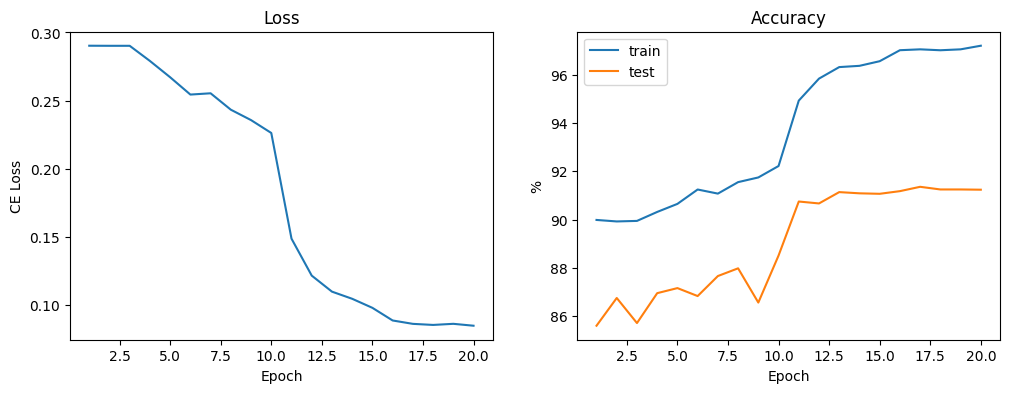

In [10]:
# 繪製Fine-tuning結果圖
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(history["train_losses"]) + 1)

fig1, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_losses"])
axes[1].plot(
    epochs, np.multiply(np.array(history["train_accuracies"]), 100), label="train"
)
axes[1].plot(
    epochs, np.multiply(np.array(history["test_accuracies"]), 100), label="test"
)

# plot config
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("CE Loss")

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("%")
axes[1].legend()

plt.savefig("train_prune_model.png", dpi=150, bbox_inches="tight")
plt.show()

## FLOPs & Parameters

In [11]:
!pip install thop
!pip install torchsummary

In [12]:
from thop import profile
from torchsummary import summary

##### 使用 thop 計算 FLOPs 和參數數量 #####
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
model = model.to(device)

dummy_input = torch.randn(1, 3, 32, 32).to(device)
flops, params = profile(model, inputs=(dummy_input,))

print(f"FLOPs: {flops}")
print(f"Params: {params}")
summary(model, input_size=(3, 32, 32))

Device: cuda
[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.pooling.MaxPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
FLOPs: 191762932.0
Params: 6789697.0
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
         MaxPool2d-4           [-1, 64, 16, 16]           

In [13]:
import pandas as pd

orig_params = 23513162
orig_flops = 328947712
orig_acc = 90.43  

pruned_acc_before_ft = 90.51  

ft_params = params 
ft_flops = flops  
ft_acc = best_prec1 * 100 

param_reduction = (1 - ft_params / orig_params) * 100
flops_reduction = (1 - ft_flops / orig_flops) * 100

comparison_data = {
    "Model": ["Original ResNet50", "Pruned (Before FT)", "Pruned (Fine-tuned)"],
    "Parameters": [f"{orig_params:,}", f"{int(ft_params):,}",
    f"{int(ft_params):,}"],
    "Param Reduction (%)": ["-", f"{param_reduction:.2f}%",
    f"{param_reduction:.2f}%"],
    "FLOPs": [f"{int(orig_flops):,}", f"{int(ft_flops):,}", f"{int(ft_flops):,}"],
    "FLOPs Reduction (%)": ["-", f"{flops_reduction:.2f}%",
    f"{flops_reduction:.2f}%"],
    "Test Accuracy (%)": [f"{orig_acc:.2f}%", f"{pruned_acc_before_ft:.2f}%",
    f"{ft_acc:.2f}%"],
    "Acc vs Original (%)": ["-", f"{pruned_acc_before_ft - orig_acc:+.2f}%",
    f"{ft_acc - orig_acc:+.2f}%"],
}

df = pd.DataFrame(comparison_data)

display(df)

print("\n=== Markdown Format ===")
print(df.to_markdown(index=False))

,Model,Parameters,Param Reduction (%),FLOPs,FLOPs Reduction (%),Test Accuracy (%),Acc vs Original (%)
0,Original ResNet50,"23,513,162",-,"328,947,712",-,90.43%,-
1,Pruned (Before FT),"6,789,697",71.12%,"191,762,932",41.70%,90.51%,+0.08%
2,Pruned (Fine-tuned),"6,789,697",71.12%,"191,762,932",41.70%,91.36%,+0.93%



=== Markdown Format ===
| Model               | Parameters   | Param Reduction (%)   | FLOPs       | FLOPs Reduction (%)   | Test Accuracy (%)   | Acc vs Original (%)   |
|:--------------------|:-------------|:----------------------|:------------|:----------------------|:--------------------|:----------------------|
| Original ResNet50   | 23,513,162   | -                     | 328,947,712 | -                     | 90.43%              | -                     |
| Pruned (Before FT)  | 6,789,697    | 71.12%                | 191,762,932 | 41.70%                | 90.51%              | +0.08%                |
| Pruned (Fine-tuned) | 6,789,697    | 71.12%                | 191,762,932 | 41.70%                | 91.36%              | +0.93%                |
